In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

c:\Users\khushi jaiswal\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:

# Cell 2: Load cleaned dataset

df = pd.read_csv(
    r"D:\resume project\PharmaLens-AI\resume_project\data\S2_cleaned.csv"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (457225, 16)


,hf_pk,name1,date,stockout,received,consumption,closeBalance,openBalance,facility_type,lat,long,district,quarter,productID,normAvg,normStd
0,663,"Envelope, Dispensing, Plastic, 10cm x 7cm, Pcs",2019-01-10,0,0,59,0,59,MCHP,9.089409,-12.00467,Bombali,2019Q4,1,152.030426,228.309369
1,667,"Envelope, Dispensing, Plastic, 10cm x 7cm, Pcs",2019-01-10,0,0,70,0,70,CHP,8.903324,-12.04545,Bombali,2019Q4,1,152.030426,228.309369
2,745,"Envelope, Dispensing, Plastic, 10cm x 7cm, Pcs",2019-01-10,1,0,14,0,14,CHP,8.807020,-12.08181,Bombali,2019Q4,1,152.030426,228.309369
3,753,"Envelope, Dispensing, Plastic, 10cm x 7cm, Pcs",2019-01-10,0,0,100,0,100,CHP,8.791610,-12.06068,Bombali,2019Q4,1,152.030426,228.309369
4,725,"Envelope, Dispensing, Plastic, 10cm x 7cm, Pcs",2019-01-10,0,0,100,0,100,MCHP,9.032880,-12.04858,Bombali,2019Q4,1,152.030426,228.309369


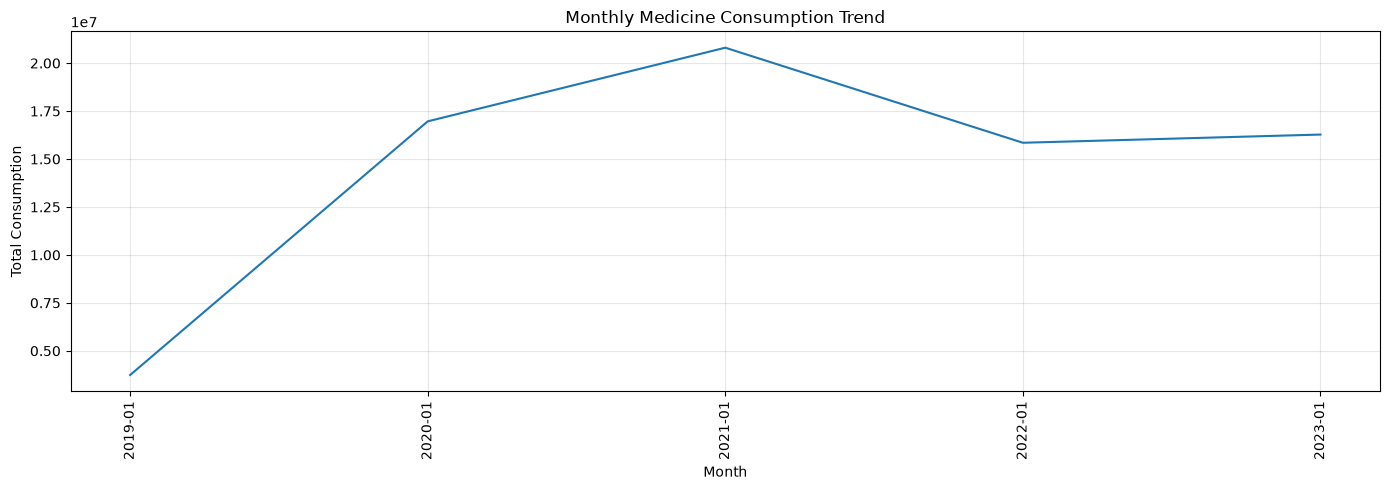

In [3]:

# Cell 3: Monthly medicine consumption trend

df["date"] = pd.to_datetime(df["date"])

monthly_consumption = (
    df.groupby(df["date"].dt.to_period("M"))["consumption"]
      .sum()
)

plt.figure(figsize=(14, 5))
plt.plot(
    monthly_consumption.index.astype(str),
    monthly_consumption.values
)

plt.title("Monthly Medicine Consumption Trend")
plt.xlabel("Month")
plt.ylabel("Total Consumption")
plt.xticks(rotation=90)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

name1
Folic Acid 5mg, Tab                                        15774051
Paracetamol (Acetaminophen) 500mg, Tab                     13436208
Paracetamol (Acetaminophen) 250mg, Dispersible, Tab        12829118
Zinc Sulphate 20mg, Dispersible, Tab                        8288536
Albendazole 400mg, Tab                                      4761658
Oral Rehydration Salts (ORS), Sachet                        4517921
Glove, Exam, Latex, Medium, Nonsterile, Disposable, Pcs     3402674
Methyldopa 250mg, Tab                                       2502174
Envelope, Dispensing, Plastic, 10cm x 7cm, Pcs              1381802
Ampicillin 500mg, Pdr for IM/IV, Inj, Vial                  1372730
Name: consumption, dtype: int64


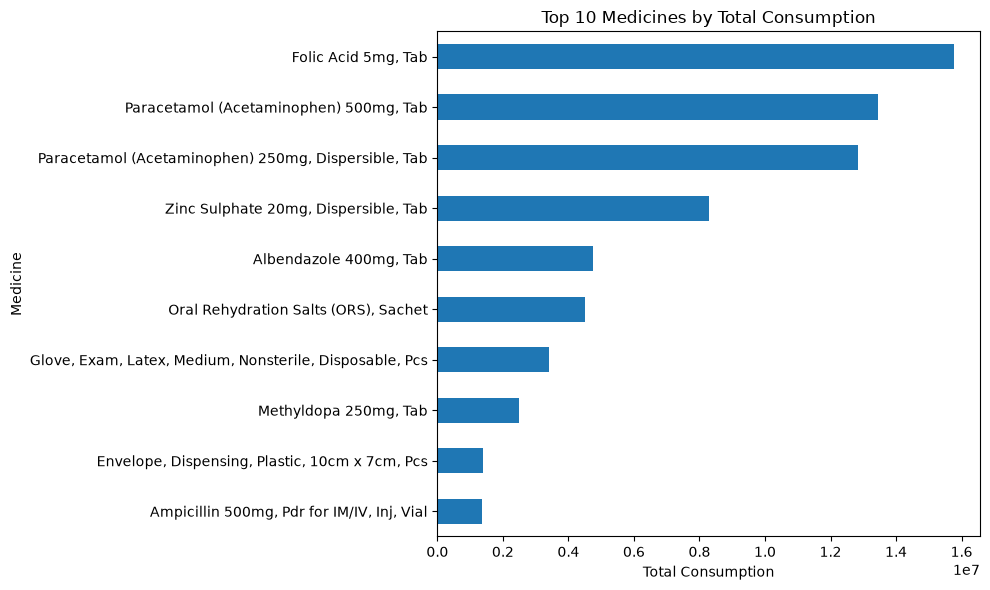

In [4]:

# Top 10 medicines by total consumption

top_medicines = (
    df.groupby("name1")["consumption"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

print(top_medicines)

top_medicines.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Medicines by Total Consumption")
plt.xlabel("Total Consumption")
plt.ylabel("Medicine")
plt.tight_layout()
plt.show()

district
Kenema       7964762
Pujehun      7756034
Bo           7373989
Port Loko    6547275
Kambia       6496426
Bombali      5131842
Tonkolili    4381946
Kono         3713340
Kailahun     3474721
Koinadugu    3391755
Name: consumption, dtype: int64


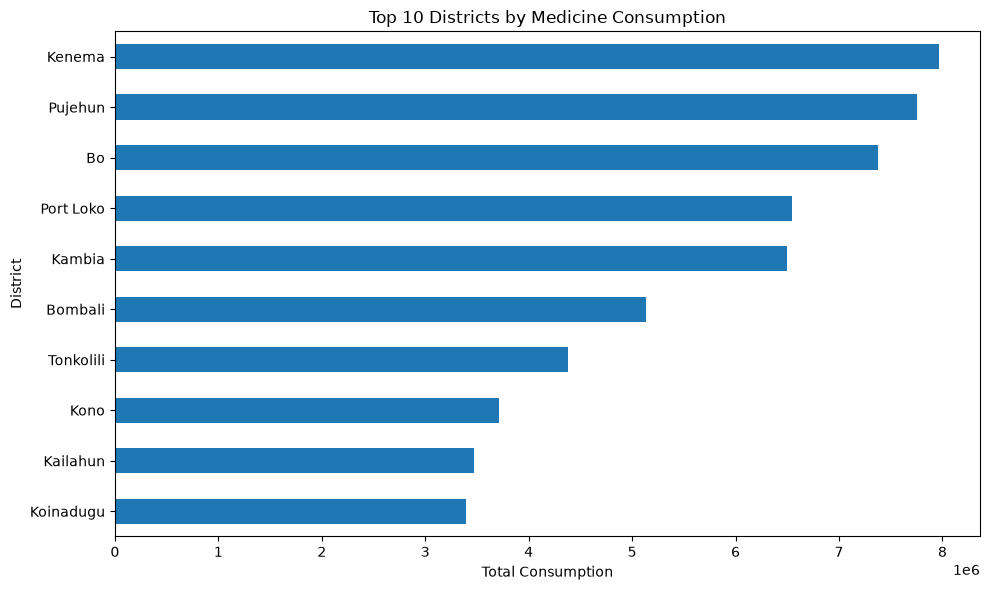

In [5]:

# Top 10 districts by total medicine consumption

district_consumption = (
    df.groupby("district")["consumption"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

print(district_consumption)

district_consumption.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Districts by Medicine Consumption")
plt.xlabel("Total Consumption")
plt.ylabel("District")
plt.tight_layout()
plt.show()

district
Bo           7166
Kenema       7136
Port Loko    5165
Kambia       4793
Bombali      4764
Kailahun     4658
Kono         4168
Pujehun      4069
Tonkolili    3401
Moyamba      3220
dtype: int64


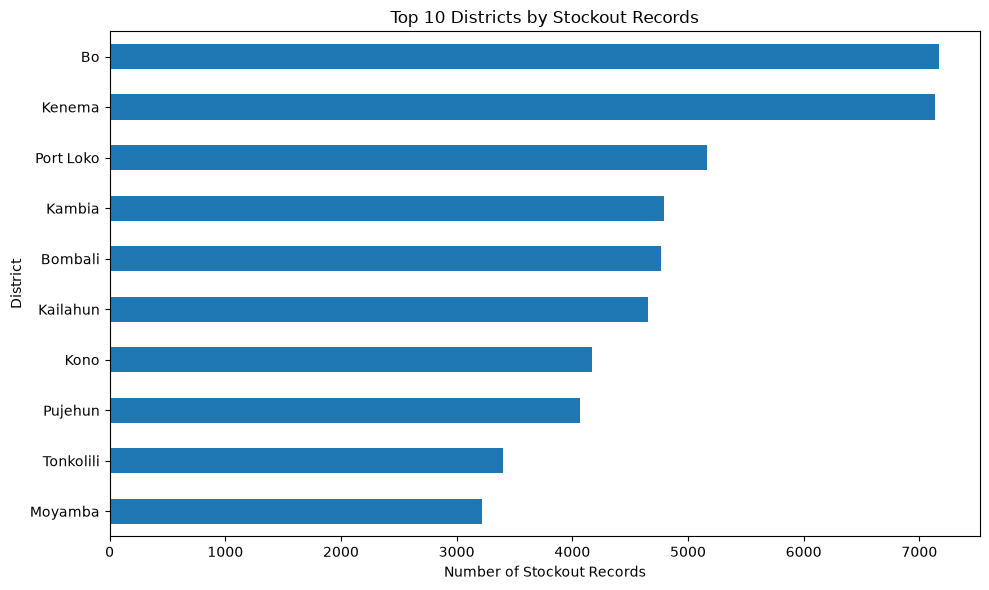

In [6]:

# Top 10 districts with the most stockout records

stockout_by_district = (
    df[df["stockout"] == 1]
    .groupby("district")
    .size()
    .sort_values(ascending=False)
    .head(10)
)

print(stockout_by_district)

stockout_by_district.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Districts by Stockout Records")
plt.xlabel("Number of Stockout Records")
plt.ylabel("District")
plt.tight_layout()
plt.show()

facility_type
MCHP        29637018
CHP         21168725
CHC         20764470
Hospital     2058565
Name: consumption, dtype: int64


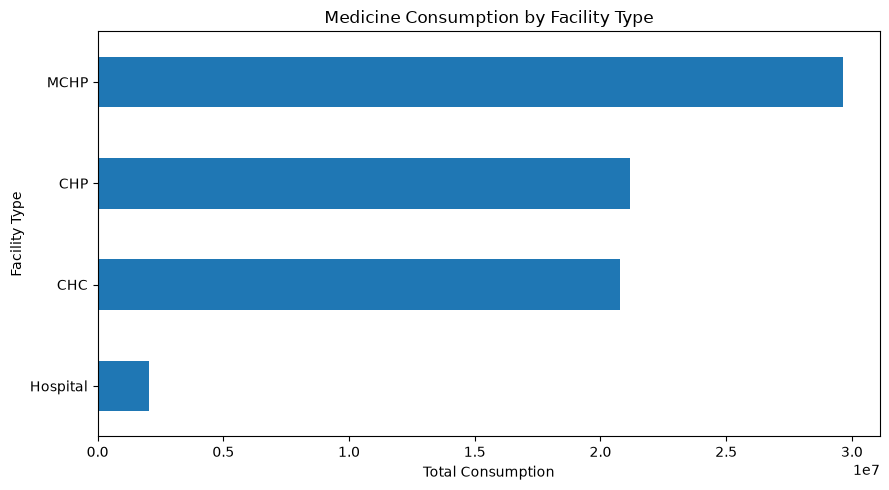

In [7]:

# Total medicine consumption by facility type

facility_consumption = (
    df.groupby("facility_type")["consumption"]
      .sum()
      .sort_values(ascending=False)
)

print(facility_consumption)

facility_consumption.sort_values().plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Medicine Consumption by Facility Type")
plt.xlabel("Total Consumption")
plt.ylabel("Facility Type")
plt.tight_layout()
plt.show()

           count        mean  median       sum
stockout                                      
0         395269  152.483461    44.0  60271985
1          61956  215.585141    80.0  13356793


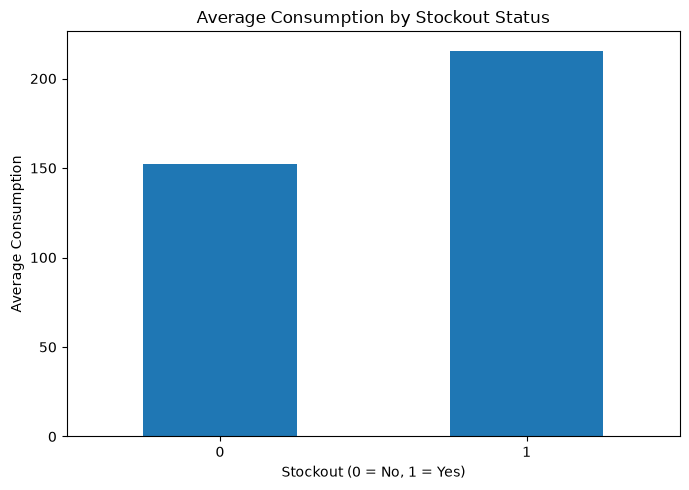

In [8]:

# Compare consumption by stockout status

stockout_analysis = df.groupby("stockout")["consumption"].agg(
    ["count", "mean", "median", "sum"]
)

print(stockout_analysis)

stockout_analysis["mean"].plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Average Consumption by Stockout Status")
plt.xlabel("Stockout (0 = No, 1 = Yes)")
plt.ylabel("Average Consumption")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

name1
Paracetamol (Acetaminophen) 500mg, Tab                     575.377184
Folic Acid 5mg, Tab                                        510.354957
Ferrous Sulphate 200mg, Tab                                506.412968
Paracetamol (Acetaminophen) 250mg, Dispersible, Tab        461.313125
Zinc Sulphate 20mg, Dispersible, Tab                       218.544956
Glove, Exam, Latex, Medium, Nonsterile, Disposable, Pcs    182.792049
Ciprofloxacin 500mg, Tab                                   171.215834
Aluminium Hydroxide 500mg, Tab                             167.478261
Metoclopramide HCl 10mg, Tab                               150.659877
Envelope, Dispensing, Plastic, 10cm x 7cm, Pcs             149.545671
Name: consumption, dtype: float64


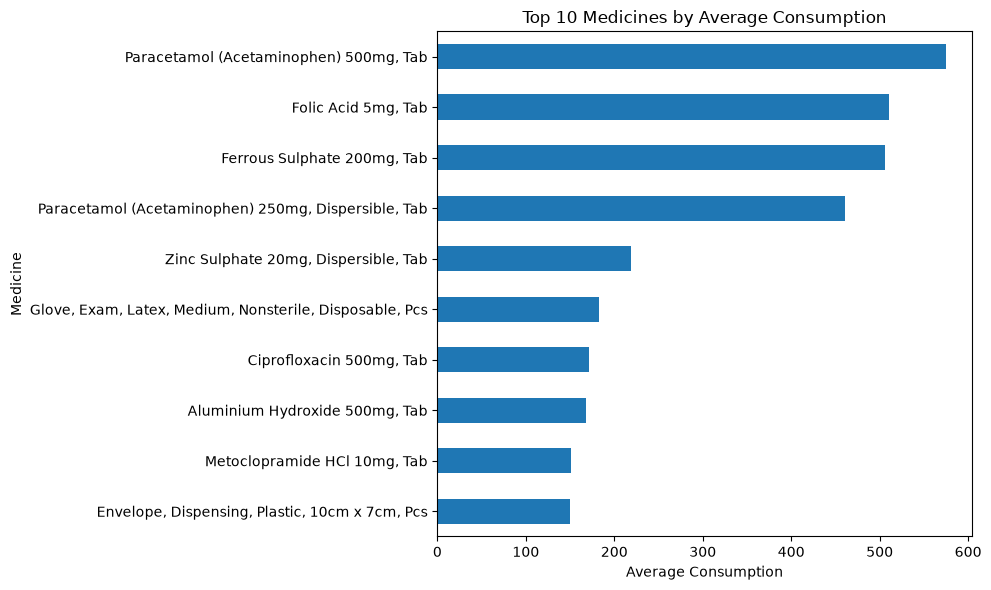

In [9]:

# Top 10 medicines by average consumption

avg_medicine_consumption = (
    df.groupby("name1")["consumption"]
      .mean()
      .sort_values(ascending=False)
      .head(10)
)

print(avg_medicine_consumption)

avg_medicine_consumption.sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Medicines by Average Consumption")
plt.xlabel("Average Consumption")
plt.ylabel("Medicine")
plt.tight_layout()
plt.show()

date
2019Q1     3738300
2020Q1    16963806
2021Q1    20804052
2022Q1    15847319
2023Q1    16275301
Freq: Q-DEC, Name: consumption, dtype: int64


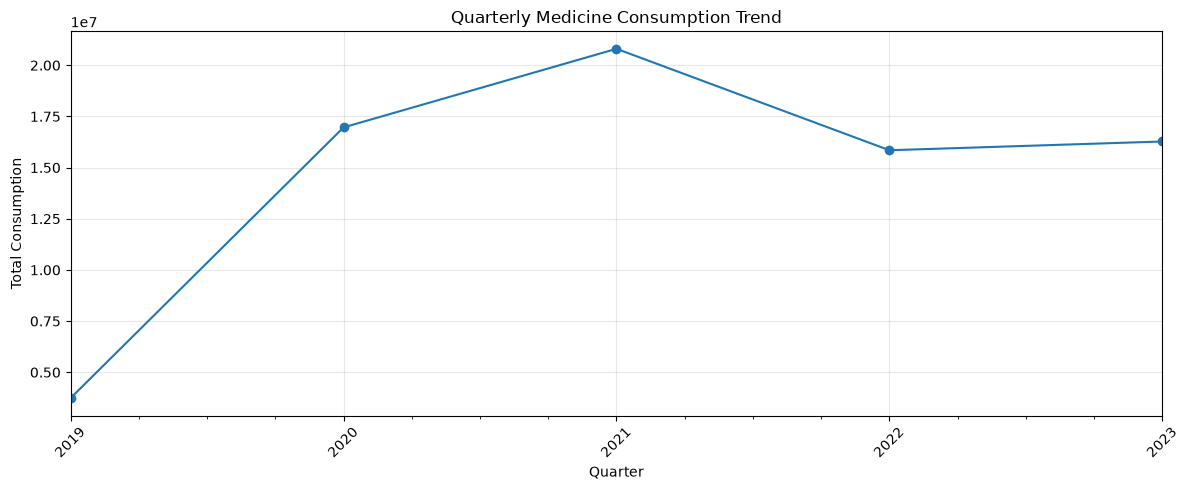

In [10]:

# Quarterly medicine consumption

quarterly_consumption = (
    df.groupby(df["date"].dt.to_period("Q"))["consumption"]
      .sum()
)

print(quarterly_consumption)

quarterly_consumption.plot(
    figsize=(12, 5),
    marker="o"
)

plt.title("Quarterly Medicine Consumption Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Consumption")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

               total_records  stockout_records  stockout_rate_pct
facility_type                                                    
CHP                   138520             19765              14.27
MCHP                  215432             28857              13.39
CHC                   101256             13273              13.11
Hospital                2017                61               3.02


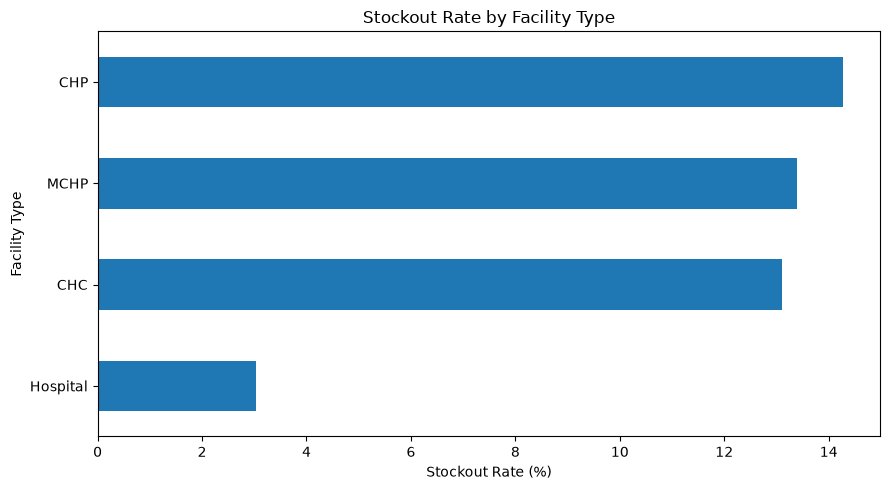

In [11]:

# Stockout rate by facility type

facility_stockout = (
    df.groupby("facility_type")
      .agg(
          total_records=("stockout", "size"),
          stockout_records=("stockout", "sum")
      )
)

facility_stockout["stockout_rate_pct"] = (
    facility_stockout["stockout_records"]
    / facility_stockout["total_records"] * 100
)

facility_stockout = facility_stockout.sort_values(
    "stockout_rate_pct", ascending=False
)

print(facility_stockout.round(2))

facility_stockout["stockout_rate_pct"].sort_values().plot(
    kind="barh", figsize=(9, 5)
)

plt.title("Stockout Rate by Facility Type")
plt.xlabel("Stockout Rate (%)")
plt.ylabel("Facility Type")
plt.tight_layout()
plt.show()

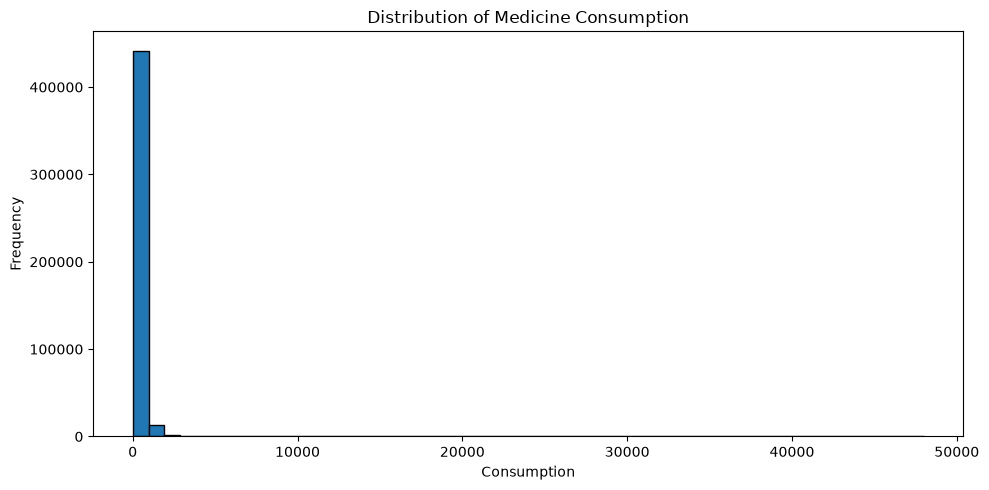

In [12]:

# Distribution of medicine consumption

plt.figure(figsize=(10, 5))

plt.hist(df["consumption"], bins=50, edgecolor="black")

plt.title("Distribution of Medicine Consumption")
plt.xlabel("Consumption")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()